# LENVI2007 — Q2 & Q3: cooker geometry and solar optics (critical review)

**A reproducible study guide, not just code.** Prepared from the Q1 EPW result, theoretical lecture, project brief.

**Assignment references**: *LENVI2007B APP Solar Cooker*, pp. 1–4, Q2–Q3; N. Parmentier, *Solar Thermal Energy — Theoretical Concepts*, slides 12–16, 18–24, 28, 30, 43–44.

**Research references**: A. Harmim et al. (2013), *Solar Energy* 98, pp. 422–433, DOI 10.1016/j.solener.2013.09.019; R. K. Goyal and M. Eswaramoorthy (2023), *Materials Today: Proceedings* 72, pp. 1047–1055, DOI 10.1016/j.matpr.2022.09.160; B. C. Anilkumar & R. Maniyeri (2025), *Sådhanå* 50:334, DOI 10.1007/s12046-025-02990-w.

**Key outputs at start (optimistic two-pane case):** $A_{ap}=0.560\ \mathrm{m^2}$, $A_m=0.480\ \mathrm{m^2}$, $P_{receiver,abs}\approx531.7\ \mathrm W$, $\eta_{0,gross}\approx0.7382$. Literature-informed glazing sensitivity gives a materially lower absorbed power.

## 1. Python tools and reproducibility

**Why this section exists.** `numpy` handles 3-D rays and solar angles, `pandas` handles EnergyPlus weather intervals, and `matplotlib` draws engineering figures. The model is intentionally written with explicit formulas rather than hiding the optical calculation in a black-box library.

**Check for yourself.** Make sure the CISM kernel has `numpy`, `pandas`, `matplotlib`; no external web connection is necessary. The original `.epw` file must be uploaded alongside the notebook.

In [28]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle



### Additional construction details

The two cover panes are assumed **4 mm thick each**, separated by an approximately **10 mm air gap** (Harmim et al. use double 4-mm glazing; Goyal & Eswaramoorthy model a 10-mm glass gap). The **0.5-mm aluminium absorber sheet** is an affordable thin-sheet candidate, consistent with examples discussed in the 2025 solar-box-cooker review. A **10-mm wood shell**, 50-mm mineral-wool insulation and lidded food-safe aluminium pot are proposed. Their precise density, mass and thermal conductivities must be verified when Q4 and Q5 are built. This adds constructible specifications without claiming these exact materials were measured.

## 2. Cooker geometry, physical assumptions and sources

**Assigned design constraints** (assignment pp. 1–2): a box cooker using **flat** mirrors, no motors, no auxiliary heat, common materials. This notebook proposes a 0.80 m (E–W) × 0.70 m (N–S) horizontal aperture with **one flat mirror** hinged on its **north side** (mirror: 0.80 × 0.60 m along its surface). The inward cavity depth is 0.25 m, insulated side/base thickness 0.05 m, and indicative lidded aluminium pot dimensions are 0.22 m diameter × 0.13 m high.

$$A_{ap}=0.80(0.70)=0.560\ \mathrm{m^2},\qquad A_m=0.80(0.60)=0.480\ \mathrm{m^2}.$$

**Crucial material distinction:** lecture slide 14 lists black paint at $\alpha_{sol}=0.97$, $\varepsilon_{IR}=0.97$. The first is relevant to solar optical absorption; the second matters in Q4 thermal emission. Reflectance $\rho_m=0.85$ follows the worked example on lecture slide 50, but is **not a manufacturer measurement**. Insulation $k\approx0.04$ W/(m·K) is a lecture/paper representative value (lecture slide 34; Harmim et al., 2013, Table 3). Actual wood conductivity and pot mass require specification before thermal simulation.

**Double-glazing caution:** $\tau_{cover}=0.85$ is an optimistic **effective total** transmitted fraction for both sheets. Goyal & Eswaramoorthy (2023), Table 2, give $\tau=0.84$ for each of two modeled glass surfaces; the rough independent two-pane product would be $0.84^2=0.7056$. The latter is examined as a sensitivity case. Transmittance actually depends on wavelength and incidence angle (lecture slides 12–16; Harmim 2013, §6.3). Neither number is a certified product specification.

**Why not import the CPC shape from the papers?** Harmim (2013) and Goyal & Eswaramoorthy (2023) study **compound parabolic concentrators**, which the assignment forbids. Their materials, modelling philosophy and performance-test methods are informative, but their optical geometry must **not** be copied.

**Model scope:** the optical "receiver" groups black absorber plate and dark pot exterior; it is not the power directly transferred into the food.

In [29]:
# Three assignment-level inputs: no other changes needed for another EPW/date/time.
EPW_FILE = Path("BEL_VLG_Beauvechain.AP.064580_TMYx.2011-2025.epw")
DESIGN_DATE = "2026-06-24"
START_STANDARD_TIME = "11:30"   # local STANDARD time (CET), never CEST

# The period here is only an inspection window. Q5 determines cooking time.
INSPECTION_HOURS = 5.0
TIME_STEP_MIN = 10
MANUAL_AIM_INTERVAL_MIN = 30

# Geometry: horizontal glazed aperture, north-hinged single flat mirror.
AP_EW_M, AP_NS_M = 0.80, 0.70
MIRROR_EW_M, MIRROR_SLOPE_LENGTH_M = 0.80, 0.60
BOX_INTERIOR_DEPTH_M, INSULATION_M = 0.25, 0.05
POT_DIAMETER_M, POT_HEIGHT_M = 0.22, 0.13
# Additional buildable details for Q2; all are preliminary design choices.
GLASS_PANE_THICKNESS_M = 0.004  # Harmim et al. 2013: 4 mm glazing example
AIR_GAP_BETWEEN_PANES_M = 0.010 # Goyal and Eswaramoorthy: 10 mm example
ABSORBER_SHEET_THICKNESS_M = 0.0005 # 2025 review example: thin sheet metal
WOOD_CASING_THICKNESS_M = 0.010 # low-tech preliminary wood casing
POT_MASS_KG = 0.50            # preliminary, verify against actual vessel
POT_CP_J_KG_K = 900.0        # approximate aluminium specific heat capacity

# Source / justified preliminary assumptions, not measured products.
MIRROR_SOLAR_REFLECTANCE = 0.85  # slide 50 example
COVER_SOLAR_TRANSMITTANCE = 0.85 # OPTIMISTIC combined transmittance of BOTH panes; scenario benchmark
SINGLE_PANE_PAPER_TRANSMITTANCE = 0.84 # Goyal & Eswaramoorthy (2023), Table 2, nominal PER pane
COVER_CONSERVATIVE = SINGLE_PANE_PAPER_TRANSMITTANCE**2  # ~0.7056; neglect multiple internal reflections
RECEIVER_SOLAR_ABSORPTANCE = 0.97 # black paint, slide 14
RECEIVER_IR_EMISSIVITY = 0.97   # black paint, for later heat-loss analysis
INSULATION_CONDUCTIVITY_W_MK = 0.04 # mineral wool illustrative, slide 34
GROUND_REFLECTANCE = 0.20      # slide 28; contribution zero when aperture is horizontal

# Restrict mirror to outward-leaning or vertical: no overhang above aperture.
ALLOWED_MIRROR_TILTS_DEG = np.arange(45, 91, 1)
AIMING_METHOD = "interval_energy"  # "instant" reproduces the user's previous schedule;
# "interval_energy" chooses the fixed tilt maximizing mirror energy over each 30-min interval.
RAY_SAMPLES_X, RAY_SAMPLES_SLOPE = 81, 61
EVALUATE_SENSITIVITY = True
OUTPUT_DIR = Path("LENVI2007_Q2_Q3_CRITICAL_results")

# The study specifies Louvain-la-Neuve for the Beauvechain weather station.
# For a different EPW, use weather station's coordinates automatically.
STUDY_SITE_BY_WMO = {"064580": (50.67, 4.61)}

assert 0 < COVER_SOLAR_TRANSMITTANCE <= 1
assert 0 < MIRROR_SOLAR_REFLECTANCE <= 1
assert 0 < RECEIVER_SOLAR_ABSORPTANCE <= 1
assert 0 < MANUAL_AIM_INTERVAL_MIN and TIME_STEP_MIN > 0
assert MANUAL_AIM_INTERVAL_MIN % TIME_STEP_MIN == 0
assert AIMING_METHOD in {"instant", "interval_energy"}
assert np.all((ALLOWED_MIRROR_TILTS_DEG >= 0) & (ALLOWED_MIRROR_TILTS_DEG <= 90))
APERTURE_AREA_M2 = AP_EW_M * AP_NS_M
MIRROR_AREA_M2 = MIRROR_EW_M * MIRROR_SLOPE_LENGTH_M

MATERIALS = pd.DataFrame([
    {"Component": "North booster", "Material": "specular aluminium foil / mirrored sheet", "Parameter": "solar reflectance rho_m", "Value": MIRROR_SOLAR_REFLECTANCE, "Unit": "-", "Evidence": "lecture p. 50 illustrative 0.85; compare Goyal 2023 Table 2 value 0.96"},
    {"Component": "Glazed cover", "Material": "two low-iron glass panes", "Parameter": "effective solar transmittance tau", "Value": COVER_SOLAR_TRANSMITTANCE, "Unit": "-", "Evidence": "OPTIMISTIC assumption for both panes combined; test conservative scenario"},
    {"Component": "Absorber/pot exterior", "Material": "black-painted metal", "Parameter": "solar absorptance alpha", "Value": RECEIVER_SOLAR_ABSORPTANCE, "Unit": "-", "Evidence": "theoretical concepts p. 14; Harmim 2013 Table 3 uses alpha=0.95"},
    {"Component": "Absorber/pot exterior", "Material": "black-painted metal", "Parameter": "infrared emissivity epsilon", "Value": RECEIVER_IR_EMISSIVITY, "Unit": "-", "Evidence": "theoretical concepts p. 14; Harmim 2013 Table 3 uses alpha=0.95"},
    {"Component": "Walls/base", "Material": "encapsulated mineral wool", "Parameter": "thermal conductivity k", "Value": INSULATION_CONDUCTIVITY_W_MK, "Unit": "W/(m K)", "Evidence": "lecture p.34, Harmim 2013 Table 3 gives k=0.04 W/(m K)"},
    {"Component": "Casing", "Material": "wood frame and enclosure", "Parameter": "wood conductivity (indicative)", "Value": "0.1–0.2", "Unit": "W/(m K)", "Evidence": "range, slide 34"},
    {"Component": "Glazed cover", "Material": "two simple clear/low-iron glass sheets", "Parameter": "pane thickness / air gap", "Value": "4 / 10", "Unit": "mm", "Evidence": "preliminary; Harmim 2013 4-mm panes; Goyal 2023 10-mm gap"},
    {"Component": "Interior absorber", "Material": "black-painted thin aluminium sheet", "Parameter": "sheet thickness", "Value": 0.5, "Unit": "mm", "Evidence": "candidate; Anilkumar & Maniyeri 2025 review thin-sheet examples"},
    {"Component": "Wood casing", "Material": "plywood or simple timber board", "Parameter": "casing thickness", "Value": 10.0, "Unit": "mm", "Evidence": "preliminary design choice"},
    {"Component": "Vessel", "Material": "food-safe aluminium pot with lid", "Parameter": "diameter / height", "Value": f"{POT_DIAMETER_M:.2f} / {POT_HEIGHT_M:.2f}", "Unit": "m", "Evidence": "design assumption"},
    {"Component": "Vessel", "Material": "food-safe aluminium pot with lid", "Parameter": "pot mass / cp", "Value": f"{POT_MASS_KG:.2f} / {POT_CP_J_KG_K:.0f}", "Unit": "kg / J/(kg K)", "Evidence": "preliminary mass and typical Al cp; use in later Q5 after validation"},
])



## 3. Import weather and station metadata

**Theory / source**: Q1 and lecture slides 18–24. The EPW LOCATION header gives station latitude, longitude, time-zone offset and WMO ID. The hourly records use `Hour=1..24`, indicating the *end* of each hour. Thus `Hour=12` supplies the 11:00–12:00 CET interval at 11:30.

**Why the source-year field is not the design year:** the Beauvechain TMYx uses June data taken from 2020. It is a stitched representative weather year, while the project evaluates solar position on its specified design calendar day. The weather data are reused at the requested month/day/hour.

**Assumption:** hourly GHI/DNI/DHI are held constant over each hour, and solar angles are recalculated every 10 minutes. Avoid presenting the result as 10-minute measured weather.

In [30]:
# Equivalent EPW parsing/solar-time conventions to documented Q1 notebook.
def read_epw(path):
    if not path.exists():
        raise FileNotFoundError(f"EPW not found: {path}. Upload it beside this notebook.")
    with path.open(encoding="utf-8-sig", newline="") as f:
        loc = next(csv.reader(f))
    if loc[0].upper().strip() != "LOCATION":
        raise ValueError("Input file is not an EPW file")
    meta = {
        "station": loc[1], "wmo": loc[5], "lat": float(loc[6]),
        "lon": float(loc[7]), "utc_offset": float(loc[8]),
        "elevation_m": float(loc[9]),
    }
    col_inds = [0, 1, 2, 3, 4, 6, 13, 14, 15, 21]
    col_names = ["source_year", "month", "day", "hour_end", "minute",
                 "air_C", "GHI", "DNI", "DHI", "wind_ms"]
    weather = pd.read_csv(path, skiprows=8, header=None, usecols=col_inds,
                          names=col_names, low_memory=False)
    for col in col_names:
        weather[col] = pd.to_numeric(weather[col], errors="raise")
    if not weather.hour_end.between(1, 24).all():
        raise ValueError("EPW end-labelled hours must lie in 1..24")
    if not weather.minute.isin([0,60]).all():
        raise ValueError("Expected hourly EPW file with minute field 0 or 60")
    return meta, weather


def weather_on_grid(raw, grid):
    # END-labelled EPW row hour=12 covers [11:00,12:00) local standard time.
    parts = []
    for year in range(grid[0].year - 1, grid[-1].year + 2):
        dates = pd.to_datetime({"year": year, "month": raw.month,
                                "day": raw.day}, errors="coerce")
        valid = dates.notna()
        p = raw.loc[valid].copy()
        p["period_end"] = dates.loc[valid] + pd.to_timedelta(p.hour_end, unit="h")
        p["period_start"] = p.period_end - pd.Timedelta(hours=1)
        parts.append(p)
    intervals = pd.concat(parts, ignore_index=True).sort_values("period_start")
    out = pd.merge_asof(pd.DataFrame({"time_CET": grid}), intervals,
                        left_on="time_CET", right_on="period_start",
                        direction="backward")
    if out.period_end.isna().any() or (out.time_CET >= out.period_end).any():
        raise ValueError("Missing EPW hour(s) covering the requested time window")
    if not out[["GHI","DNI","DHI"]].ge(0).all().all():
        raise ValueError("Negative/missing radiation value in relevant EPW records")
    return out



## 4. Sun position and angular convention

Slides 19 and 21:

$$\delta=23.45^\circ\sin\!\left(\frac{360^\circ(284+n)}{365}\right),\quad
\omega=15^\circ(t_{sol}-12),$$
$$\cos\theta_z=\cos\phi\cos\delta\cos\omega+\sin\phi\sin\delta.$$

Solar time is calculated from **standard local clock time** (never daylight saving) using longitude and equation of time. The course uses **solar azimuth 0° at south, negative east, positive west**. Cartesian vectors use $x=$east, $y=$north, $z=$up; the resulting unit vector points **toward** the Sun. An incoming ray travels in the opposite direction $-\mathbf{s}$.

**Independent check:** at 11:30 CET on 24 June in Louvain-la-Neuve, $\theta_z\approx30.75^\circ$, $\gamma_s\approx-34.47^\circ$. If your numbers differ strongly, check degrees/radians and azimuth signs.

In [31]:
# Slide 19: Cooper declination & Spencer equation of time.
# Slide 21: zenith and south-zero azimuth. x=East, y=North, z=Up.
def solar_geometry(times, latitude, longitude, utc_offset):
    times = pd.DatetimeIndex(times)
    n = times.dayofyear.to_numpy(dtype=float)
    standard_hour = (times.hour + times.minute/60.0
                     + times.second/3600.0).to_numpy(dtype=float)
    B = np.deg2rad(360*(n-1)/365)
    EoT = 229.2*(0.000075 + 0.001868*np.cos(B)
             - 0.032077*np.sin(B) - 0.014615*np.cos(2*B)
             - 0.04089*np.sin(2*B))
    correction = 4*(longitude-15*utc_offset) + EoT  # east-positive longitudes
    solar_hour = standard_hour + correction/60.0
    omega_deg = 15*(solar_hour-12)
    decl_deg = 23.45*np.sin(np.deg2rad(360*(284+n)/365))
    phi, delta, omega = map(np.deg2rad, (latitude, decl_deg, omega_deg))
    cosz = np.sin(phi)*np.sin(delta) + np.cos(phi)*np.cos(delta)*np.cos(omega)
    zenith = np.rad2deg(np.arccos(np.clip(cosz, -1, 1)))
    altitude = 90 - zenith
    az = np.rad2deg(np.arctan2(np.sin(omega),
                 np.cos(omega)*np.sin(phi)-np.tan(delta)*np.cos(phi)))
    az = np.where(altitude > 0, az, np.nan) # lecture: south=0, east negative
    azi_rad, alt_rad = np.deg2rad(az), np.deg2rad(altitude)
    direction_to_sun = np.column_stack([
        -np.cos(alt_rad)*np.sin(azi_rad),
        -np.cos(alt_rad)*np.cos(azi_rad),
        np.sin(alt_rad)])
    geo = pd.DataFrame({"solar_time_decimal_h": solar_hour,
        "declination_deg": decl_deg, "hour_angle_deg": omega_deg,
        "zenith_deg": zenith, "solar_altitude_deg": altitude,
        "azimuth_southzero_deg": az,
        "azimuth_northcw_deg": (az+180) % 360,
        "cos_zenith": np.maximum(0, cosz)})
    return geo, direction_to_sun



## 5. Flat-mirror law of reflection and finite-aperture interception

**Lecture slide 30** approximates the mirror addition through $\rho_m\gamma\,DNI\cos\theta_m A_m$. (irradiance directe normale DNI = G_bn) The fraction $\gamma$ cannot reasonably be assumed equal to 1: a flat mirror illuminates a translated footprint and some reflected beam may miss the window.

Mirror normal $\mathbf n$ is defined by its outward (north) tilt $\beta_m$; the cosine of the beam incidence angle is $\mu_m=\max(0,\mathbf{s}\cdot\mathbf n)$. The **outgoing reflected ray** is

$$\mathbf r=-\mathbf s+2(\mathbf s\cdot\mathbf n)\mathbf n.$$

Sample a uniformly spaced two-dimensional grid over the true **physical mirror surface**, trace each ray to the plane of the horizontal glass ($z=0$), and count whether it lies within $|x|\le0.4$ m, $|y|\le0.35$ m. The fraction of valid samples is $\gamma$.

**Independent mathematical limits:** if $DNI=0$, reflection power must be zero; $0\le\gamma\le1$. We also check how $\gamma$ changes when the number of rays increases.

**Excluded effects**: mirror surface roughness, multiple reflections, supports/frame shadows, incidence-dependent cover losses, pot-specific absorption and internal cavity distribution. These are uncertainties, not measured efficiency losses in the baseline.

In [32]:
# Exact direction for ideal specular reflection; interception via finite ray samples.
# Mirror hinge: north edge (y=+AP_NS/2), mirror slopes away from box (+y).
def trace_north_mirror(dni, direction_to_sun, tilt_deg, nx=RAY_SAMPLES_X,
                       ns=RAY_SAMPLES_SLOPE, return_points=False,
                       mirror_reflectance=MIRROR_SOLAR_REFLECTANCE):
    if not (0 <= tilt_deg <= 90):
        raise ValueError("Outward hinged mirror tilt must be 0..90 degrees")
    theta = np.deg2rad(tilt_deg)
    n_m = np.array([0, -np.sin(theta), np.cos(theta)])
    mu = float(np.dot(direction_to_sun, n_m))
    if (not np.isfinite(mu)) or mu <= 0 or direction_to_sun[2] <= 0 or dni <= 0:
        empty = (0., 0., 0., 0.)
        return (*empty, None) if return_points else empty
    p_mirror_inc = float(dni*MIRROR_AREA_M2*mu)
    p_mirror_reflected = mirror_reflectance*p_mirror_inc
    # incident ray travels FROM Sun to mirror: -s; specular outgoing direction:
    reflected = -direction_to_sun + 2*mu*n_m
    if reflected[2] >= -1.e-12:
        vals = (p_mirror_inc, p_mirror_reflected, 0., 0.)
        return (*vals, None) if return_points else vals
    # midpoint quadrature over equal-area samples of the mirror.
    X, U = np.meshgrid(
        ((np.arange(nx)+.5)/nx-.5)*MIRROR_EW_M,
        ((np.arange(ns)+.5)/ns)*MIRROR_SLOPE_LENGTH_M
    )
    Y = AP_NS_M/2 + U*np.cos(theta)
    Z = U*np.sin(theta)
    distance = -Z/reflected[2] # intersect glazing plane z=0
    hit_x = X+distance*reflected[0]
    hit_y = Y+distance*reflected[1]
    reaches_glazing = ((distance>0)&(np.abs(hit_x)<=AP_EW_M/2)
                                      &(np.abs(hit_y)<=AP_NS_M/2))
    gamma = float(reaches_glazing.mean())
    vals = (p_mirror_inc, p_mirror_reflected,
            p_mirror_reflected*gamma, gamma)
    return (*vals, (hit_x, hit_y, reaches_glazing)) if return_points else vals


def best_manual_tilt(dni, sun):
    if sun[2] <= 0 or dni <= 0:
        return np.nan
    useful = [trace_north_mirror(dni, sun, tilt)[2]
              for tilt in ALLOWED_MIRROR_TILTS_DEG]
    return float(ALLOWED_MIRROR_TILTS_DEG[int(np.argmax(useful))])



## 6. Weather-dependent geometry and manual mirror adjustment

At each 10-minute model time, find the Sun direction from Q1, then calculate the **horizontal aperture irradiance** using **measured EPW GHI**:

$$G_T=GHI\quad\text{for }\beta_{ap}=0^\circ.$$

As a diagnostic, lecture slide 23 gives $GHI\simeq DNI\cos\theta_z+DHI$. Instantaneous $\theta_z$ and hourly-average radiation are not exactly synchronous, so use this as a plausibility check **not a substitute** for EPW GHI.

**Manual adjustment:** mirror orientation changes only every 30 minutes and stays fixed between adjustments. Two options are provided: `instant` maximizes power at the adjustment instant (original method); `interval_energy` optimizes the **sum of useful mirror power over the next half hour**, respecting the actual manual schedule. The latter is selected for the final recommended procedure because the engineer wants *energy collected over time*, not a single-frame optimum. The schedule is **not motorized tracking**.

In [33]:
start = pd.Timestamp(f"{DESIGN_DATE} {START_STANDARD_TIME}")
end = start + pd.Timedelta(hours=INSPECTION_HOURS)
times = pd.date_range(start, end, freq=f"{TIME_STEP_MIN}min")
if times[-1] != end:
    times = times.append(pd.DatetimeIndex([end]))
meta, weather_raw = read_epw(EPW_FILE)
solar_lat, solar_lon = STUDY_SITE_BY_WMO.get(meta["wmo"], (meta["lat"],meta["lon"]))
df = weather_on_grid(weather_raw, times)
geo, sun_vectors = solar_geometry(times,solar_lat,solar_lon,meta["utc_offset"])
df = pd.concat([df.reset_index(drop=True), geo.reset_index(drop=True)],axis=1)

# A horizontal aperture has G_T=GHI; do not recompute it using an
# instantaneous zenith paired with hourly mean DNI/DHI.
df["G_T_Wm2"] = df["GHI"]
df["GHI_reconstructed_instant_Wm2"] = df.DNI*df.cos_zenith + df.DHI

# The mirror is adjusted ONLY every 30 minutes and HELD FIXED in between.
# The interval_energy option is a practical improvement over instantaneous aiming:
# optimize the summed intercepted direct-beam energy of the NEXT interval.
# Zero-order-hold EPW forcing is consistent with the Q1 adopted convention.
angles, schedule = [], []
previous_tilt = float(ALLOWED_MIRROR_TILTS_DEG[0])
for i, (t, sun, dni) in enumerate(zip(times, sun_vectors, df.DNI)):
    elapsed_minutes = (t-start).total_seconds()/60
    if i == 0 or abs(elapsed_minutes % MANUAL_AIM_INTERVAL_MIN) < 1e-8:
        if i < len(times)-1:  # Do not schedule an unnecessary move at the last sample.
            if AIMING_METHOD == "instant":
                recommended = best_manual_tilt(float(dni), sun)
            else:
                window_end = min(t+pd.Timedelta(minutes=MANUAL_AIM_INTERVAL_MIN),end)
                candidate_idx = [j for j in range(i,len(times)-1)
                                 if times[j] < window_end]
                if not candidate_idx:
                    candidate_idx = [i]
                total_mirror_watts = []
                for tilt in ALLOWED_MIRROR_TILTS_DEG:
                    total_mirror_watts.append(sum(
                        trace_north_mirror(float(df.DNI.iloc[j]),sun_vectors[j],tilt)[2]
                        for j in candidate_idx))
                recommended = float(ALLOWED_MIRROR_TILTS_DEG[np.argmax(total_mirror_watts)])
            if np.isfinite(recommended):
                previous_tilt = recommended
            schedule.append({"time_CET":t,"tilt_from_horizontal_deg":previous_tilt})
    angles.append(previous_tilt)
df["mirror_tilt_deg"] = angles

power = np.array([trace_north_mirror(float(dni),sun,tilt)
    for dni,sun,tilt in zip(df.DNI,sun_vectors,df.mirror_tilt_deg)])
df[["mirror_incident_W","mirror_reflected_W","mirror_enters_aperture_W",
    "mirror_intercept_gamma"]] = power

df["aperture_incident_W"] = APERTURE_AREA_M2*df.G_T_Wm2
df["cover_incident_W"] = df.aperture_incident_W + df.mirror_enters_aperture_W
df["mirror_reflectance_loss_W"] = df.mirror_incident_W - df.mirror_reflected_W
df["mirror_missed_aperture_W"] = df.mirror_reflected_W - df.mirror_enters_aperture_W
# Optical loss components are kept SEPARATE for Q6.
df["glass_nontransmitted_W"] = (1-COVER_SOLAR_TRANSMITTANCE)*df.cover_incident_W
df["glass_transmitted_W"] = COVER_SOLAR_TRANSMITTANCE*df.cover_incident_W
df["receiver_unabsorbed_W"] = (1-RECEIVER_SOLAR_ABSORPTANCE)*df.glass_transmitted_W
df["receiver_absorbed_W"] = RECEIVER_SOLAR_ABSORPTANCE*df.glass_transmitted_W
df["abs_direct_aperture_W"] = (COVER_SOLAR_TRANSMITTANCE*
    RECEIVER_SOLAR_ABSORPTANCE*df.aperture_incident_W)
df["abs_reflected_mirror_W"] = (COVER_SOLAR_TRANSMITTANCE*
    RECEIVER_SOLAR_ABSORPTANCE*df.mirror_enters_aperture_W)
df["external_incident_W"] = df.aperture_incident_W + df.mirror_incident_W
# Gross efficiency including projected incident solar power on BOTH surfaces.
df["eta0_gross"] = df.receiver_absorbed_W / df.external_incident_W.replace(0,np.nan)
# Aperture-normalized gain useful for subsequent lumped thermal model.
# NOT an energy-conversion efficiency; may exceed 1 with mirrors.
df["absorbed_per_aperture_Wm2"] = df.receiver_absorbed_W / APERTURE_AREA_M2
df["eta0_aperture_normalized"] = df.receiver_absorbed_W / df.aperture_incident_W.replace(0,np.nan)

df["optical_balance_error_W"] = df.external_incident_W - (
    df.mirror_reflectance_loss_W + df.mirror_missed_aperture_W
    + df.glass_nontransmitted_W + df.receiver_unabsorbed_W
    + df.receiver_absorbed_W)



## 7. Solar optical power and energy closure

The flat-mirror equation of slide 30 is applied as

$$P_{ap}=G_TA_{ap},\qquad P_{m,inc}=DNI\,A_m\max(0,\mathbf{s}\cdot\mathbf{n}),$$
$$P_{m,hit}=\rho_m\gamma P_{m,inc},\qquad
P_{receiver,abs}=\alpha_{sol}\tau_{cover}\big(P_{ap}+P_{m,hit}\big).$$

For the **gross** optical efficiency, use total incident beam on the projected mirror *plus* incident GHI on the aperture:

$$\boxed{\eta_{0,gross}=\frac{P_{receiver,abs}}{P_{ap}+P_{m,inc}}}.$$

Also report the **aperture-normalized absorbed flux** $P_{receiver,abs}/A_{ap}$, and the aperture-normalized gain ratio $P_{receiver,abs}/P_{ap}$. The latter can exceed one with mirrors and is **not** an energy-conversion efficiency.

**Optical budget** at each time:

$$P_{ap}+P_{m,inc}=P_{mirror\ reflectance\ loss}+P_{mirror\ miss}+P_{cover\ nontransmitted}+P_{receiver\ unabsorbed}+P_{receiver\ absorbed}.$$

**Critical physical caution:** *cover non-transmission* groups glass reflection AND glass absorption. Heat absorbed by the glass is not automatically lost to ambient; Q4 and Q6 must resolve any retained glazing heat. Likewise, the receiver is the pot-plus-absorber black surfaces: these optics equations alone do not determine the fraction that actually strikes the pot or heats the water.

In [34]:
assert np.all(df.mirror_intercept_gamma.between(0,1)), "Interception fraction invalid"
assert np.all(df.eta0_gross.dropna().between(0,1)), "Gross optical efficiency invalid"
assert np.max(np.abs(df.optical_balance_error_W))<1e-8, "Optical budget does not close"
# Independent checks: mirror cannot redirect diffuse light in this specular model.
assert trace_north_mirror(0,sun_vectors[0],df.mirror_tilt_deg.iloc[0])[2] == 0
assert np.isclose(df.receiver_absorbed_W.iloc[0],
    df.abs_direct_aperture_W.iloc[0] + df.abs_reflected_mirror_W.iloc[0])

first = df.iloc[0]
print(f"Weather station: {meta['station']} (WMO {meta['wmo']})")
print(f"Cooker site used: lat={solar_lat:.5f} N, lon={solar_lon:.5f} E")
print(f"Q2: A_ap={APERTURE_AREA_M2:.3f} m²; A_m={MIRROR_AREA_M2:.3f} m²; "
      f"one north-hinged outward-leaning flat mirror; first tilt={first.mirror_tilt_deg:.0f}°")
print("Q3 AT START OF COOKING (local STANDARD time)")
for name in ["G_T_Wm2","DNI","DHI","aperture_incident_W",
             "mirror_incident_W","mirror_reflected_W","mirror_intercept_gamma",
             "mirror_enters_aperture_W","abs_direct_aperture_W","abs_reflected_mirror_W",
             "receiver_absorbed_W","eta0_gross","eta0_aperture_normalized"]:
    print(f"  {name:34} {first[name]:11.4f}")
print(f"Optical energy-balance residual: {float(df.optical_balance_error_W.abs().max()):.2e} W")
print("\nMATERIAL PROPERTIES AND THEIR STATUS")
print(MATERIALS.to_string(index=False))
print("\nMANUAL AIMING SCHEDULE")
sched = pd.DataFrame(schedule)
print(sched.to_string(index=False))

# Convergence check: initial mirror useful gain at 4 quadrature resolutions.
res_tests = []
for nx, ns in [(41,31),(81,61),(161,121),(241,181)]:
    inc, refl, hit, gamma = trace_north_mirror(
        float(first.DNI),sun_vectors[0],float(first.mirror_tilt_deg),nx=nx,ns=ns)
    res_tests.append({"ray_nx":nx,"ray_nl":ns,"samples":nx*ns,
                      "gamma":gamma,"mirror_hit_W":hit})
resolution_check = pd.DataFrame(res_tests)
print("\nRAY-TRACING RESOLUTION CHECK")
print(resolution_check.to_string(index=False))

# Control comparison, at start: mirror versus no mirror.
no_mirror = float(first.abs_direct_aperture_W)
with_mirror = float(first.receiver_absorbed_W)
print(f"\nWithout mirror: {no_mirror:.2f} W absorbed")
print(f"With mirror:    {with_mirror:.2f} W absorbed")
print(f"Initial power increase: {100*(with_mirror/no_mirror - 1):.1f}%")



Weather station: Beauvechain.AP (WMO 064580)
Cooker site used: lat=50.67000 N, lon=4.61000 E
Q2: A_ap=0.560 m²; A_m=0.480 m²; one north-hinged outward-leaning flat mirror; first tilt=76°
Q3 AT START OF COOKING (local STANDARD time)
  G_T_Wm2                               852.0000
  DNI                                   821.0000
  DHI                                   134.0000
  aperture_incident_W                   477.1200
  mirror_incident_W                     243.1325
  mirror_reflected_W                    206.6626
  mirror_intercept_gamma                  0.8118
  mirror_enters_aperture_W              167.7644
  abs_direct_aperture_W                 393.3854
  abs_reflected_mirror_W                138.3217
  receiver_absorbed_W                   531.7072
  eta0_gross                              0.7382
  eta0_aperture_normalized                1.1144
Optical energy-balance residual: 1.14e-13 W

MATERIAL PROPERTIES AND THEIR STATUS
            Component                            

## 8. Engineering critique, glazing sensitivity and time-integrated diagnostic

**Literature versus chosen parameters:** Harmim et al. (2013), Table 3, use absorber $\alpha=0.95$ and study a double-glazed, glass-wool-insulated box. Goyal & Eswaramoorthy (2023), Table 2, list mirror reflectance 0.96, per-surface glass transmittance 0.84 and absorber absorptivity 0.94 in a CPC-based system. We deliberately **do not copy CPC geometry**. The figures serve as parameter ranges and reasons for sensitivity, not validated values for our materials.

We compare at the project start: optimistic combined double-glass $\tau=0.85$ (original solution), approximate two-layer $\tau=0.84^2$, absorber $\alpha=0.95$, and a no-mirror control. This demonstrates the consequences of parameter uncertainty. A separate sensitivity to mirror orientation/interception should later be considered.

For the 5-hour **inspection** window (not yet $t_{cook}$), energy is integrated using a left-end-point rectangle rule at 10-minute steps:

$$E\approx\sum_{k=0}^{N-1}P(t_k)\Delta t.$$

Do not include the final timestamp as a full extra interval: the last sample is an endpoint only. This produces energy-budget inputs for Q6 but should be rerun over the actual cooking interval determined in Q5.

**Pot clearance check**: volume of an ideal cylinder is $V=\pi d^2h/4$; a real pot needs adequate freeboard above the 2 L water and 250 g pasta, plus room for a lid and steam vents. Assume neither perfect sealing nor zero evaporation without explanation.

## 8.1. Optional incidence-angle correction for double glazing

**Why test this?** The horizontal direct beam enters the glass at solar zenith $\theta_z$, while rays from the steeply tilted booster may strike the glazing at a much larger angle. Slides 12–16 and Harmim et al. (2013, §6.3) make clear that cover optical transmission is angle-dependent. A constant 0.85 transmittance is an *idealized first model*.

For an approximate check, compute the **unpolarized Fresnel reflectance** of an air–glass interface using Snell's law ($n_{glass}=1.52$, engineering assumption) and scale the normal-incidence transmittance by the ratio of four interface transmissions (two panes, two interfaces per pane). The code evaluates the Sun's and mirror beam's incidence angles separately. The diffuse part of GHI stays at the nominal transmittance because we have not simulated its angular sky distribution.

This is an **illustrative angular sensitivity**, not a measurement: it omits absorption dispersion and repeated multiple internal reflections. It must not be confused with a validated material specification. The originally reported 531.7 W remains the **constant-transmittance baseline** so comparisons are traceable.

In [35]:
# OPTIONAL sensitivity only. Ideal, uncoated glass: simple Fresnel reflection.
def fresnel_reflectance_air_glass(theta_deg, n_glass=1.52):
    ti = np.deg2rad(np.asarray(theta_deg, dtype=float))
    sin_t = np.clip(np.sin(ti)/n_glass, -1, 1)
    ct, ci = np.sqrt(1-sin_t**2), np.cos(ti)
    rs = (ci-n_glass*ct)/(ci+n_glass*ct)
    rp = (n_glass*ci-ct)/(n_glass*ci+ct)
    return 0.5*(rs**2+rp**2)

def relative_two_pane_transmission(theta_deg):
    # Normalized to the assumed effective transmission at normal incidence.
    R = fresnel_reflectance_air_glass(theta_deg)
    R0 = fresnel_reflectance_air_glass(0.0)
    return ((1-R)/(1-R0))**4  # four surfaces / two glass panes

mirror_incidence_cover = []
for sun, tilt in zip(sun_vectors, df.mirror_tilt_deg):
    beta = np.deg2rad(float(tilt))
    normal = np.array([0, -np.sin(beta), np.cos(beta)])
    mu = float(np.dot(sun,normal))
    reflected = -sun+2*mu*normal
    mirror_incidence_cover.append(
        np.rad2deg(np.arccos(np.clip(-reflected[2],0,1))) if reflected[2] < 0 else 90.)
df['mirror_glass_incidence_deg'] = mirror_incidence_cover
df['Fresnel_relative_direct'] = relative_two_pane_transmission(df.zenith_deg.to_numpy())
df['Fresnel_relative_mirror'] = relative_two_pane_transmission(df.mirror_glass_incidence_deg.to_numpy())
# For diagnostic power closure, use EPW GHI = (GHI-DHI) + DHI;
# diffuse transmission is kept at reference value (angular sky model not resolved).
beam_horiz = np.maximum(0, df.GHI-df.DHI)
df['receiver_absorbed_angle_scenario_W'] = (
    COVER_SOLAR_TRANSMITTANCE*RECEIVER_SOLAR_ABSORPTANCE*(
        APERTURE_AREA_M2*beam_horiz*df.Fresnel_relative_direct +
        APERTURE_AREA_M2*df.DHI +
        df.mirror_enters_aperture_W*df.Fresnel_relative_mirror))
df['angle_scenario_change_W'] = df.receiver_absorbed_angle_scenario_W-df.receiver_absorbed_W
print('\nOPTIONAL ANGLE-DEPENDENT GLAZING SENSITIVITY AT START:')
print(f'  Direct solar incidence on glass: {df.zenith_deg.iloc[0]:.2f} deg')
print(f'  Mirror-reflected beam incidence on glass: {df.mirror_glass_incidence_deg.iloc[0]:.2f} deg')
print(f'  Absorbed power with simple angular correction: {df.receiver_absorbed_angle_scenario_W.iloc[0]:.2f} W')
print(f'  Change relative to constant-tau baseline: {df.angle_scenario_change_W.iloc[0]:.2f} W')




OPTIONAL ANGLE-DEPENDENT GLAZING SENSITIVITY AT START:
  Direct solar incidence on glass: 30.75 deg
  Mirror-reflected beam incidence on glass: 55.89 deg
  Absorbed power with simple angular correction: 511.15 W
  Change relative to constant-tau baseline: -20.56 W


In [36]:
# Lower solar transmission for two panes, and lower absorptance,
# are literature-informed plausible alternatives, not measured properties.
# Do not combine two different definitions of optical efficiency.
comparison = pd.DataFrame([
    {"Case": "OPTIMISTIC BASE: effective double-glass tau=0.85, alpha=0.97",
     "tau_total": COVER_SOLAR_TRANSMITTANCE, "alpha": RECEIVER_SOLAR_ABSORPTANCE,
     "mirror_rho": MIRROR_SOLAR_REFLECTANCE},
    {"Case": "Goyal-inspired TWO layers: tau=0.84 squared, alpha=0.97",
     "tau_total": COVER_CONSERVATIVE, "alpha": RECEIVER_SOLAR_ABSORPTANCE,
     "mirror_rho": MIRROR_SOLAR_REFLECTANCE},
    {"Case": "Harmim-inspired black receiver: tau=0.85, alpha=0.95",
     "tau_total": COVER_SOLAR_TRANSMITTANCE, "alpha": 0.95,
     "mirror_rho": MIRROR_SOLAR_REFLECTANCE},
    {"Case": "No mirror: tau=0.85, alpha=0.97",
     "tau_total": COVER_SOLAR_TRANSMITTANCE, "alpha": RECEIVER_SOLAR_ABSORPTANCE,
     "mirror_rho": 0.0},
])
comparison["Qabs_start_W"] = [
    float(row.tau_total*row.alpha*(first.aperture_incident_W +
        first.mirror_enters_aperture_W*(row.mirror_rho/MIRROR_SOLAR_REFLECTANCE)))
    for _,row in comparison.iterrows()
]
# For no-mirror case the incident-energy denominator is aperture power only.
comparison["gross_eta_start"] = [
    q/(float(first.aperture_incident_W+first.mirror_incident_W)
       if rho > 0 else float(first.aperture_incident_W))
    for q,rho in zip(comparison.Qabs_start_W,comparison.mirror_rho)
]
# Integrated energy over [start,end): use each 10-minute model state as constant
# on its FOLLOWING 10-minute interval. Do not double-count the end point.
dt_s = (times[1]-times[0]).total_seconds()
energy_cols = ["aperture_incident_W","mirror_incident_W","mirror_reflectance_loss_W",
 "mirror_missed_aperture_W","glass_nontransmitted_W","receiver_unabsorbed_W",
 "receiver_absorbed_W","external_incident_W"]
energy_summary = pd.DataFrame({"Quantity":energy_cols,
    "Energy_kJ":[float(df[c].iloc[:-1].sum()*dt_s/1000) for c in energy_cols]})
print("\nCRITICAL LITERATURE-BASED OPTICAL SCENARIOS (AT START):")
print(comparison.round(4).to_string(index=False))
print("\nPROVISIONAL 5-HOUR ENERGY TOTALS (NOT FINAL COOKING PERIOD):")
print(energy_summary.round(2).to_string(index=False))
assert abs(energy_summary.loc[energy_summary.Quantity=="external_incident_W","Energy_kJ"].iloc[0] -
           energy_summary.loc[energy_summary.Quantity.isin([
            "mirror_reflectance_loss_W","mirror_missed_aperture_W",
            "glass_nontransmitted_W","receiver_unabsorbed_W",
            "receiver_absorbed_W"]),"Energy_kJ"].sum()) < 1e-6
# Pot geometric capacity: minimum 2 L water plus 250 g pasta, headspace required.
pot_capacity_L = np.pi*(POT_DIAMETER_M/2)**2*POT_HEIGHT_M*1000
print(f"\nEstimated straight-cylinder internal pot volume: {pot_capacity_L:.2f} L")
print("Actual usable capacity must be checked using real pot dimensions and lid clearance.")




CRITICAL LITERATURE-BASED OPTICAL SCENARIOS (AT START):
                                                        Case  tau_total  alpha  mirror_rho  Qabs_start_W  gross_eta_start
OPTIMISTIC BASE: effective double-glass tau=0.85, alpha=0.97     0.8500   0.97        0.85      531.7072           0.7382
     Goyal-inspired TWO layers: tau=0.84 squared, alpha=0.97     0.7056   0.97        0.85      441.3795           0.6128
        Harmim-inspired black receiver: tau=0.85, alpha=0.95     0.8500   0.95        0.85      520.7441           0.7230
                             No mirror: tau=0.85, alpha=0.97     0.8500   0.97        0.00      393.3854           0.8245

PROVISIONAL 5-HOUR ENERGY TOTALS (NOT FINAL COOKING PERIOD):
                 Quantity  Energy_kJ
      aperture_incident_W    7533.79
        mirror_incident_W    3886.80
mirror_reflectance_loss_W     583.02
 mirror_missed_aperture_W     663.78
   glass_nontransmitted_W    1526.07
    receiver_unabsorbed_W     259.43
      receiv

## 9. Reproducible engineering outputs

Export a time-series CSV with **all intermediate powers, optical loss categories, incident angle geometry and mirror orientation**, a tilt schedule, starting-time summary and sensitivity scenarios. Future Q4–Q6 calculations should read the *time-series*, not manually enter the 531.7 W starting value as though solar power remained constant.

**Important:** the final 5-hour window is provisional. Update it when Q5 establishes a cooking time; time-dependent absorbed power is essential for the thermal model.

In [37]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
df.to_csv(OUTPUT_DIR/"Q2_Q3_time_series.csv",index=False)
sched.to_csv(OUTPUT_DIR/"Q2_manual_tilt_schedule.csv",index=False)
MATERIALS.to_csv(OUTPUT_DIR/"Q2_material_properties.csv",index=False)
resolution_check.to_csv(OUTPUT_DIR/"Q3_ray_convergence.csv",index=False)
comparison.to_csv(OUTPUT_DIR/"Q3_glazing_absorber_scenarios.csv",index=False)
energy_summary.to_csv(OUTPUT_DIR/"Q3_5hour_energy_diagnostic.csv",index=False)
start_summary = pd.DataFrame([{
    "time_CET": str(first.time_CET),
    "Aperture_area_m2": APERTURE_AREA_M2,
    "Mirror_area_m2": MIRROR_AREA_M2,
    "Mirror_count": 1,
    "Starting_mirror_tilt_deg": first.mirror_tilt_deg,
    "G_T_Wm2": first.G_T_Wm2,
    "Mirror_entering_aperture_W": first.mirror_enters_aperture_W,
    "Receiver_absorbed_W": first.receiver_absorbed_W,
    "Gross_optical_efficiency": first.eta0_gross,
    "Combined_glazing_tau_assumed": COVER_SOLAR_TRANSMITTANCE,
    "Conservative_two_pane_tau": COVER_CONSERVATIVE,
    "Aperture_normalized_gain_Wm2": first.absorbed_per_aperture_Wm2,
}])
start_summary.to_csv(OUTPUT_DIR/"Q2_Q3_starting_summary.csv",index=False)



## 10. Figures: drawing, ray footprint and performance curves

The following code produces two dimensioned views of the proposed box and mirror, a power-flow plot, interception and efficiency curves, and a mirror-spot footprint. Mirror elevation is measured **above horizontal** and the Sun must strike the **front** of the mirror.

**Interpretation:** if the fraction of reflected rays hitting the glazed aperture falls with time even though the tilt is re-aimed, the limiting issue may be east–west solar azimuth misalignment. A single hinge about an east–west line cannot steer east–west. A second manual degree of freedom or different mirror arrangement would improve interception but increase low-tech complexity.

**Use of research papers:** compare your qualitative physics to Harmim's measured improvement with reflectors (2013, Figs. 6–8), rather than comparing the numerical efficiencies literally: their CPC geometry, site, tests and efficiency denominators differ. The 2025 review by Anilkumar and Maniyeri describes storage enhancements, but a PCM system is **not** assumed in this no-storage baseline.

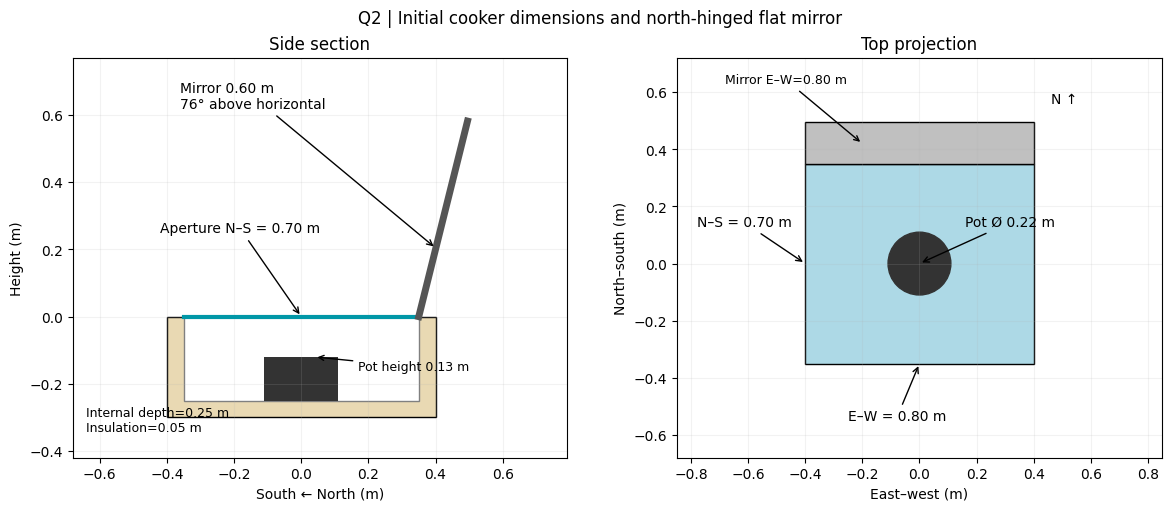

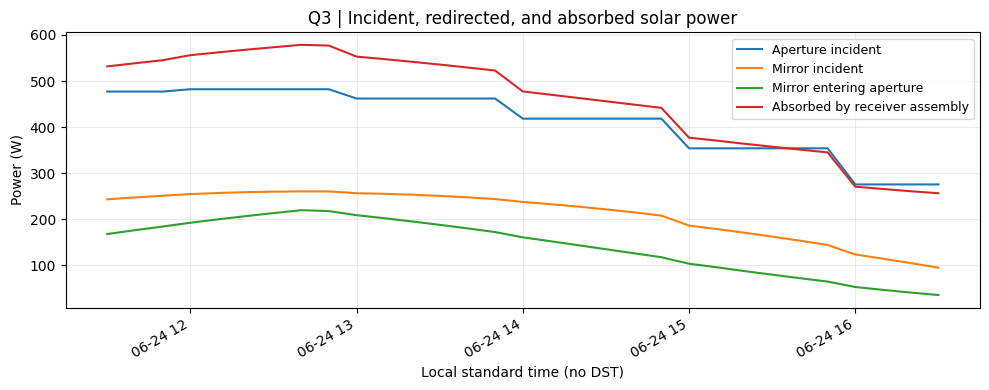

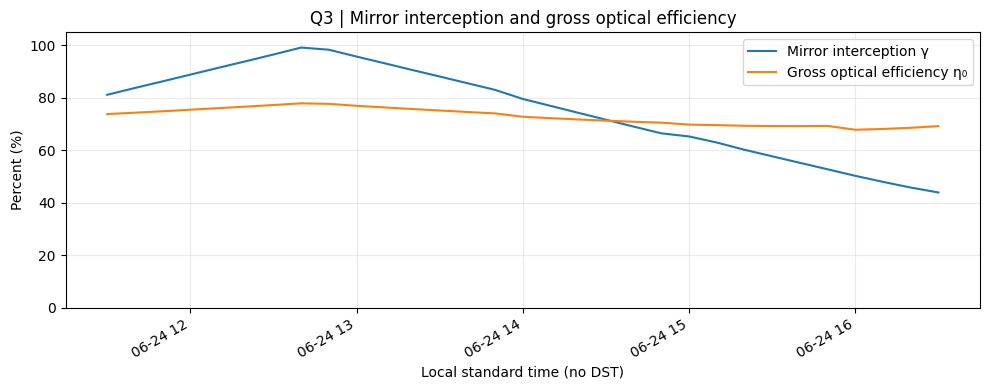

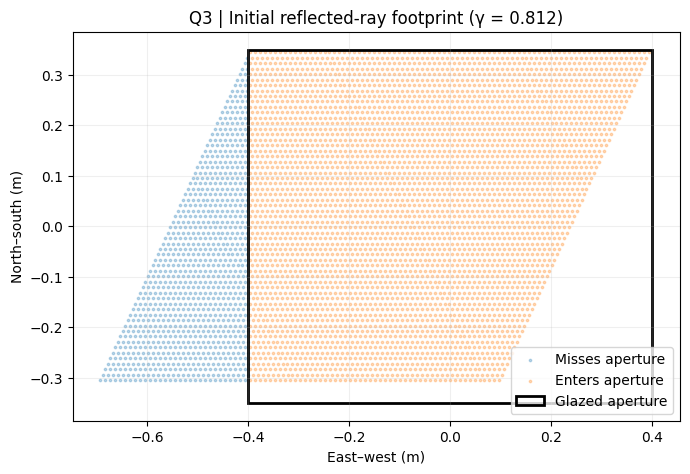


All outputs written to: C:\Users\julie\OneDrive\Bureau\Unifcour\Renewable energy\Solar\N\LENVI2007_Q2_Q3_CRITICAL_results
IMPORTANT: This is power absorbed by pot/absorber ASSEMBLY, NOT measured pot-only or water heat.
IMPORTANT: Optical cover nontransmission includes both reflection and glass absorption, 
and cannot all be counted as ENVIRONMENTAL heat loss in Q6.


In [41]:
# Dimensioned geometrical sketch — based on actual model coordinate system.
angle = np.deg2rad(float(first.mirror_tilt_deg))
fig, (ax,ax2) = plt.subplots(1,2,figsize=(12,5),layout="constrained")
ax.add_patch(Rectangle((-AP_NS_M/2-INSULATION_M,-BOX_INTERIOR_DEPTH_M-INSULATION_M),
             AP_NS_M+2*INSULATION_M,BOX_INTERIOR_DEPTH_M+INSULATION_M,
             facecolor="#e9d9b3",edgecolor="black"))
ax.add_patch(Rectangle((-AP_NS_M/2,-BOX_INTERIOR_DEPTH_M),AP_NS_M,
               BOX_INTERIOR_DEPTH_M,facecolor="white",edgecolor="grey"))
ax.plot([-AP_NS_M/2,AP_NS_M/2],[0,0],color="#0097a7",linewidth=3,label="glazing")
ax.plot([AP_NS_M/2,AP_NS_M/2+MIRROR_SLOPE_LENGTH_M*np.cos(angle)],
        [0,MIRROR_SLOPE_LENGTH_M*np.sin(angle)],color="#555555",lw=5,label="flat mirror")
ax.add_patch(Rectangle((-POT_DIAMETER_M/2,-BOX_INTERIOR_DEPTH_M),
             POT_DIAMETER_M,POT_HEIGHT_M,facecolor="#333333"))
ax.annotate(f"Mirror {MIRROR_SLOPE_LENGTH_M:.2f} m\n{first.mirror_tilt_deg:.0f}° above horizontal",
            xy=(AP_NS_M/2+.35*MIRROR_SLOPE_LENGTH_M*np.cos(angle),
                .35*MIRROR_SLOPE_LENGTH_M*np.sin(angle)),xytext=(-.36,.62),
            arrowprops={"arrowstyle":"->"})
ax.annotate(f"Aperture N–S = {AP_NS_M:.2f} m",xy=(0,0),xytext=(-.42,.25),
            arrowprops={"arrowstyle":"->"})
ax.text(-.64,-.34,f"Internal depth={BOX_INTERIOR_DEPTH_M:.2f} m\nInsulation={INSULATION_M:.2f} m",fontsize=9)
ax.annotate(f"Pot height {POT_HEIGHT_M:.2f} m",xy=(0.04,-BOX_INTERIOR_DEPTH_M+POT_HEIGHT_M),
            xytext=(.17,-.16),fontsize=9,arrowprops={"arrowstyle":"->"})
ax.set(xlim=(-.68,.79),ylim=(-.42,.77),xlabel="South ← North (m)",ylabel="Height (m)",title="Side section")
ax.set_aspect("equal");ax.grid(alpha=.16)
ax2.add_patch(Rectangle((-AP_EW_M/2,-AP_NS_M/2),AP_EW_M,AP_NS_M,
                facecolor="#add9e6",edgecolor="black"))
ax2.add_patch(Rectangle((-MIRROR_EW_M/2,AP_NS_M/2),MIRROR_EW_M,
                    MIRROR_SLOPE_LENGTH_M*np.cos(angle),facecolor="silver",edgecolor="black"))
ax2.add_patch(Circle((0,0),POT_DIAMETER_M/2,color="#333333"))
ax2.annotate(f"E–W = {AP_EW_M:.2f} m",xy=(0,-AP_NS_M/2),xytext=(-.25,-.55),arrowprops={"arrowstyle":"->"})
ax2.annotate(f"N–S = {AP_NS_M:.2f} m",xy=(-AP_EW_M/2,0),xytext=(-.78,.13),arrowprops={"arrowstyle":"->"})
ax2.annotate(f"Pot Ø {POT_DIAMETER_M:.2f} m",xy=(0,0),xytext=(.16,.13),arrowprops={"arrowstyle":"->"})
ax2.annotate(f"Mirror E–W={MIRROR_EW_M:.2f} m",xy=(-.20,AP_NS_M/2+.07),
             xytext=(-.68,.63),fontsize=9,arrowprops={"arrowstyle":"->"})
ax2.text(.46,.56,"N ↑")
ax2.set(xlim=(-.85,.85),ylim=(-.68,.72),xlabel="East–west (m)",ylabel="North–south (m)",title="Top projection")
ax2.set_aspect("equal");ax2.grid(alpha=.16)
fig.suptitle("Q2 | Initial cooker dimensions and north-hinged flat mirror")
fig.savefig(OUTPUT_DIR/"Q2_dimensioned_geometry.png",dpi=190)
plt.show();plt.close(fig)

fig, ax=plt.subplots(figsize=(10,4))
for col,label in [("aperture_incident_W","Aperture incident"),
                  ("mirror_incident_W","Mirror incident"),
                  ("mirror_enters_aperture_W","Mirror entering aperture"),
                  ("receiver_absorbed_W","Absorbed by receiver assembly")]:
    ax.plot(df.time_CET,df[col],label=label)
ax.set(title="Q3 | Incident, redirected, and absorbed solar power",xlabel="Local standard time (no DST)",ylabel="Power (W)")
ax.legend(fontsize=9);ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUTPUT_DIR/"Q3_optical_power.png",dpi=190)
plt.show();plt.close(fig)

fig, ax=plt.subplots(figsize=(10,4))
ax.plot(df.time_CET,100*df.mirror_intercept_gamma,label="Mirror interception γ")
ax.plot(df.time_CET,100*df.eta0_gross,label="Gross optical efficiency η₀")
ax.set(title="Q3 | Mirror interception and gross optical efficiency",xlabel="Local standard time (no DST)",ylabel="Percent (%)",ylim=(0,105))
ax.legend();ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(OUTPUT_DIR/"Q3_interception_efficiency.png",dpi=190)
plt.show();plt.close(fig)

_,_,_,_,hits = trace_north_mirror(float(first.DNI),sun_vectors[0],
                   float(first.mirror_tilt_deg),return_points=True)
fig, ax=plt.subplots(figsize=(7,5))
if hits is not None:
    x,y,inside = hits
    ax.scatter(x[~inside],y[~inside],s=3,alpha=.28,label="Misses aperture")
    ax.scatter(x[inside],y[inside],s=3,alpha=.28,label="Enters aperture")
ax.add_patch(Rectangle((-AP_EW_M/2,-AP_NS_M/2),AP_EW_M,AP_NS_M,
              fill=False,color="black",lw=2,label="Glazed aperture"))
ax.set(title=f"Q3 | Initial reflected-ray footprint (γ = {first.mirror_intercept_gamma:.3f})",
       xlabel="East–west (m)",ylabel="North–south (m)")
ax.grid(alpha=.2);ax.legend();ax.set_aspect("equal");fig.tight_layout()
fig.savefig(OUTPUT_DIR/"Q3_mirror_footprint.png",dpi=190)
plt.show();plt.close(fig)

print("\nAll outputs written to:",OUTPUT_DIR.resolve())
print("IMPORTANT: This is power absorbed by pot/absorber ASSEMBLY, NOT measured pot-only or water heat.")
print("IMPORTANT: Optical cover nontransmission includes both reflection and glass absorption, ")
print("and cannot all be counted as ENVIRONMENTAL heat loss in Q6.")


In [47]:

# ============================================================
# FIXED CONDITIONS FOR SENSITIVITY ANALYSIS
# ============================================================

# Select the time step with the maximum direct normal irradiance (DNI)
idx = df["DNI"].idxmax()
conditions = df.loc[idx]
sun = sun_vectors[idx]

# Solar position calculated by the model
time_selected = times[idx]
solar_altitude = conditions["solar_altitude_deg"]
solar_zenith = conditions["zenith_deg"]
solar_azimuth = conditions["azimuth_southzero_deg"]

print("=" * 60)
print("CONDITIONS USED FOR THE COMPARISON")
print("=" * 60)

print(f"Date and time: {time_selected}")
print(f"Direct Normal Irradiance (DNI): {conditions['DNI']:.2f} W/m²")
print(f"Global Horizontal Irradiance (GHI): {conditions['GHI']:.2f} W/m²")

print("\nSolar position at the selected time:")
print(f"  Solar altitude: {solar_altitude:.2f}°")
print(f"  Solar zenith angle: {solar_zenith:.2f}°")
print(f"  Solar azimuth (south = 0°): {solar_azimuth:.2f}°")

print("\nFixed optical parameters:")
print(f"  Mirror solar reflectance: {MIRROR_SOLAR_REFLECTANCE:.2f}")
print(f"  Cover solar transmittance: {COVER_SOLAR_TRANSMITTANCE:.2f}")
print(f"  Receiver solar absorptance: {RECEIVER_SOLAR_ABSORPTANCE:.2f}")

print("\nFixed geometry:")
print(f"  Aperture area: {APERTURE_AREA_M2:.3f} m²")
print(f"  Mirror area: {MIRROR_AREA_M2:.3f} m²")
print(
    f"  Allowed mirror tilt range: "
    f"{ALLOWED_MIRROR_TILTS_DEG.min()}° to "
    f"{ALLOWED_MIRROR_TILTS_DEG.max()}°"
)
print("=" * 60)








CONDITIONS USED FOR THE COMPARISON
Date and time: 2026-06-24 12:00:00
Direct Normal Irradiance (DNI): 823.00 W/m²
Global Horizontal Irradiance (GHI): 861.00 W/m²

Solar position at the selected time:
  Solar altitude: 61.47°
  Solar zenith angle: 28.53°
  Solar azimuth (south = 0°): -21.27°

Fixed optical parameters:
  Mirror solar reflectance: 0.85
  Cover solar transmittance: 0.85
  Receiver solar absorptance: 0.97

Fixed geometry:
  Aperture area: 0.560 m²
  Mirror area: 0.480 m²
  Allowed mirror tilt range: 45° to 90°


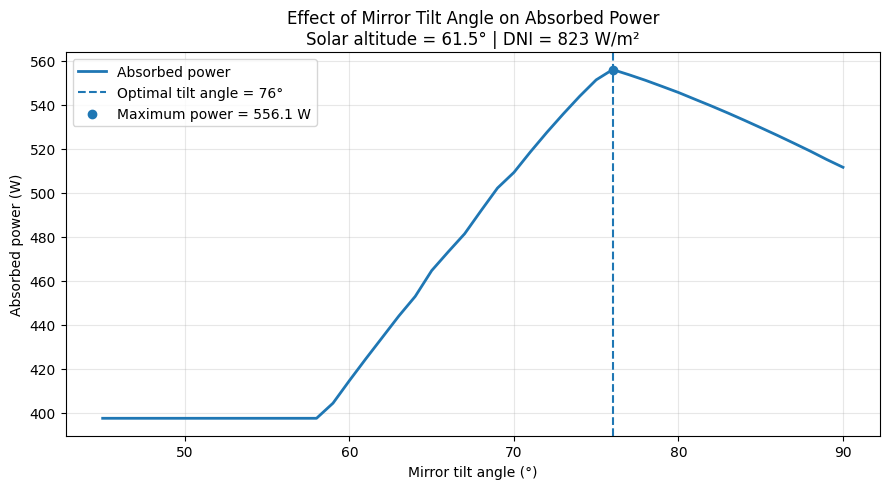

Selected time: 2026-06-24 12:00:00
Optimal mirror tilt angle: 76°
Maximum absorbed power: 556.08 W


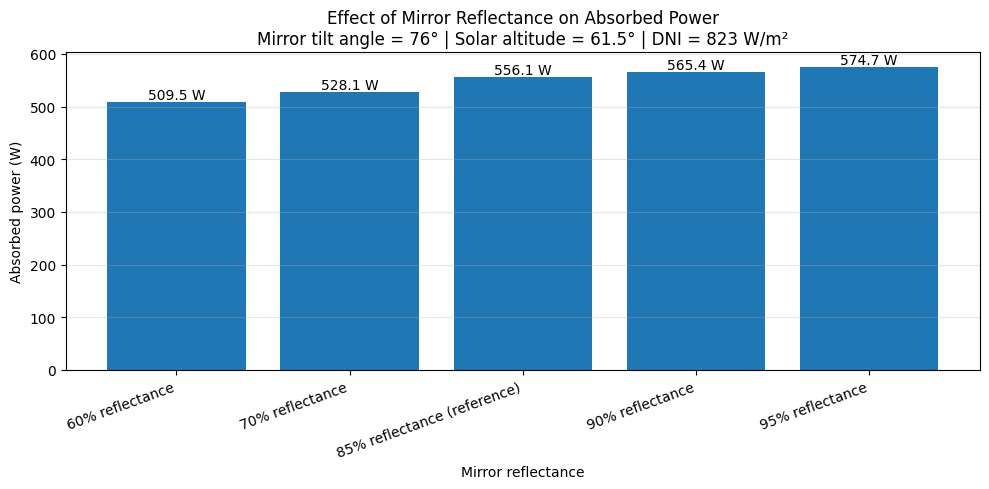

Mirror reflectance comparison:
60% reflectance: 509.45 W
70% reflectance: 528.10 W
85% reflectance (reference): 556.08 W
90% reflectance: 565.41 W
95% reflectance: 574.73 W


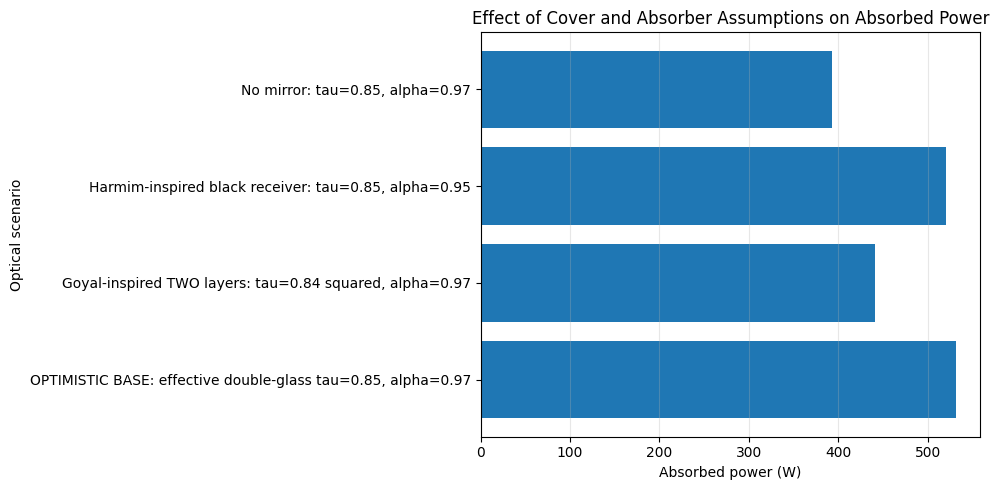

In [48]:

# ============================================================
# GRAPH 1: ABSORBED POWER VS. MIRROR TILT ANGLE
# ============================================================

# Select the time step with the maximum direct normal irradiance
idx = df["DNI"].idxmax()
conditions = df.loc[idx]
sun = sun_vectors[idx]
dni = float(conditions["DNI"])

# Test mirror tilt angles (degrees from the horizontal)
angles = np.arange(45, 91, 1)

# Directly absorbed power without the mirror
P_direct = float(conditions["abs_direct_aperture_W"])

# Calculate absorbed power for each mirror tilt angle
P_absorbed = []

for angle in angles:
    _, _, P_mirror_aperture, gamma = trace_north_mirror(
        dni, sun, angle
    )

    # Additional absorbed power due to the reflected sunlight
    P_reflected_absorbed = (
        P_mirror_aperture
        * COVER_SOLAR_TRANSMITTANCE
        * RECEIVER_SOLAR_ABSORPTANCE
    )

    P_absorbed.append(P_direct + P_reflected_absorbed)

P_absorbed = np.array(P_absorbed)

# Find the optimal mirror tilt angle
i_opt = np.argmax(P_absorbed)
angle_opt = angles[i_opt]
P_opt = P_absorbed[i_opt]

# Plot the results
plt.figure(figsize=(9, 5))

plt.plot(
    angles,
    P_absorbed,
    linewidth=2,
    label="Absorbed power"
)

plt.axvline(
    angle_opt,
    linestyle="--",
    label=f"Optimal tilt angle = {angle_opt}°"
)

plt.scatter(
    angle_opt,
    P_opt,
    zorder=3,
    label=f"Maximum power = {P_opt:.1f} W"
)

plt.xlabel("Mirror tilt angle (°)")
plt.ylabel("Absorbed power (W)")

plt.title(
    "Effect of Mirror Tilt Angle on Absorbed Power\n"
    f"Solar altitude = {solar_altitude:.1f}° | "
    f"DNI = {dni:.0f} W/m²"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected time: {conditions['time_CET']}")
print(f"Optimal mirror tilt angle: {angle_opt}°")
print(f"Maximum absorbed power: {P_opt:.2f} W")










# ============================================================
# GRAPH 2: EFFECT OF MIRROR REFLECTANCE
# ============================================================

# Compare different mirror reflectance values
# These values represent illustrative scenarios
mirror_materials = {
    "60% reflectance": 0.60,
    "70% reflectance": 0.70,
    "85% reflectance (reference)": 0.85,
    "90% reflectance": 0.90,
    "95% reflectance": 0.95,
}

material_names = []
absorbed_powers = []

for material_name, reflectance in mirror_materials.items():

    # Calculate the reflected power using the selected reflectance
    # IMPORTANT: trace_north_mirror must support mirror_reflectance
    _, _, P_mirror_aperture, gamma = trace_north_mirror(
        dni,
        sun,
        angle_opt,
        mirror_reflectance=reflectance
    )

    P_reflected_absorbed = (
        P_mirror_aperture
        * COVER_SOLAR_TRANSMITTANCE
        * RECEIVER_SOLAR_ABSORPTANCE
    )

    P_total = P_direct + P_reflected_absorbed

    material_names.append(material_name)
    absorbed_powers.append(P_total)

# Plot the results
plt.figure(figsize=(10, 5))

bars = plt.bar(material_names, absorbed_powers)

plt.ylabel("Absorbed power (W)")
plt.xlabel("Mirror reflectance")
plt.title(
    "Effect of Mirror Reflectance on Absorbed Power\n"
    f"Mirror tilt angle = {angle_opt}° | "
    f"Solar altitude = {solar_altitude:.1f}° | "
    f"DNI = {dni:.0f} W/m²"
)

plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

# Display the numerical values above the bars
for bar, value in zip(bars, absorbed_powers):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f} W",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Print the numerical results for verification
print("Mirror reflectance comparison:")
for name, power in zip(material_names, absorbed_powers):
    print(f"{name}: {power:.2f} W")








# ============================================================
# GRAPH 3: COMPARISON OF OPTICAL SCENARIOS
# ============================================================

plt.figure(figsize=(10, 5))

plt.barh(
    comparison["Case"],
    comparison["Qabs_start_W"]
)

plt.xlabel("Absorbed power (W)")
plt.ylabel("Optical scenario")
plt.title("Effect of Cover and Absorber Assumptions on Absorbed Power")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()








## 11. What the project group should conclude from Q2–Q3

**Supported calculation:** the proposed geometry can redirect a useful beam of sunlight through the finite aperture; the model determines an intercepted mirror fraction by geometric ray tracing and then estimates the absorption of a lumped black receiver assembly.

**Not established by Q2–Q3:** that the vessel receives exactly all black-surface absorbed power, that glazing transmission is precisely 0.85 for two panes, that the box reaches 95 °C, or that the pasta becomes cooked. Q4 must calculate conduction, convection and radiation, and Q5 must solve transient heat storage with the actual cooking load.

**Recommended review questions**: (i) Why is mirror power based on DNI rather than GHI? (ii) Why is a 76° mirror orientation plausible but not globally optimal? (iii) How does 0.85 total glazing transmittance differ from 0.84 per pane? (iv) What exactly is the denominator of the 73.8% gross optical efficiency? (v) Why is glazing optical non-transmission not necessarily equal to thermal loss to ambient?

**Reporting discipline:** quote inputs and calculated quantities with units, label each assumption as measured/literature-derived/engineering choice, retain all intermediate data, and explain differences from the CPC papers rather than treating their results as validation of this geometry.